In [1]:
%matplotlib inline
from pathlib import Path
from plotting_params import use_my_style
use_my_style()
import matplotlib.pyplot as plt
from pymolfit import correct
from pymolfit import Spectrum, load_spectrum, select_telluric_regions

### To correct one of the many orders you do the following.

# grab the file from one location...
FILE = Path(
    "/srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits"
)

date_dir = FILE.parent.parent.name

#...but save the order regions elsewhere
REGION_DIR = Path("/home/alst3712/clean_data") / date_dir / "order_regions"

REGION_DIR.mkdir(parents=True, exist_ok=True)


# Correcting as in fix.py

1) Load spectrum by giving filename, chip, WL col, flux col, and units
2) Make region file using function from fix_full_correction - what's the difference between select telluric regions and this??
3) Correct, giving basically the same inputs as in load_spectrum function.

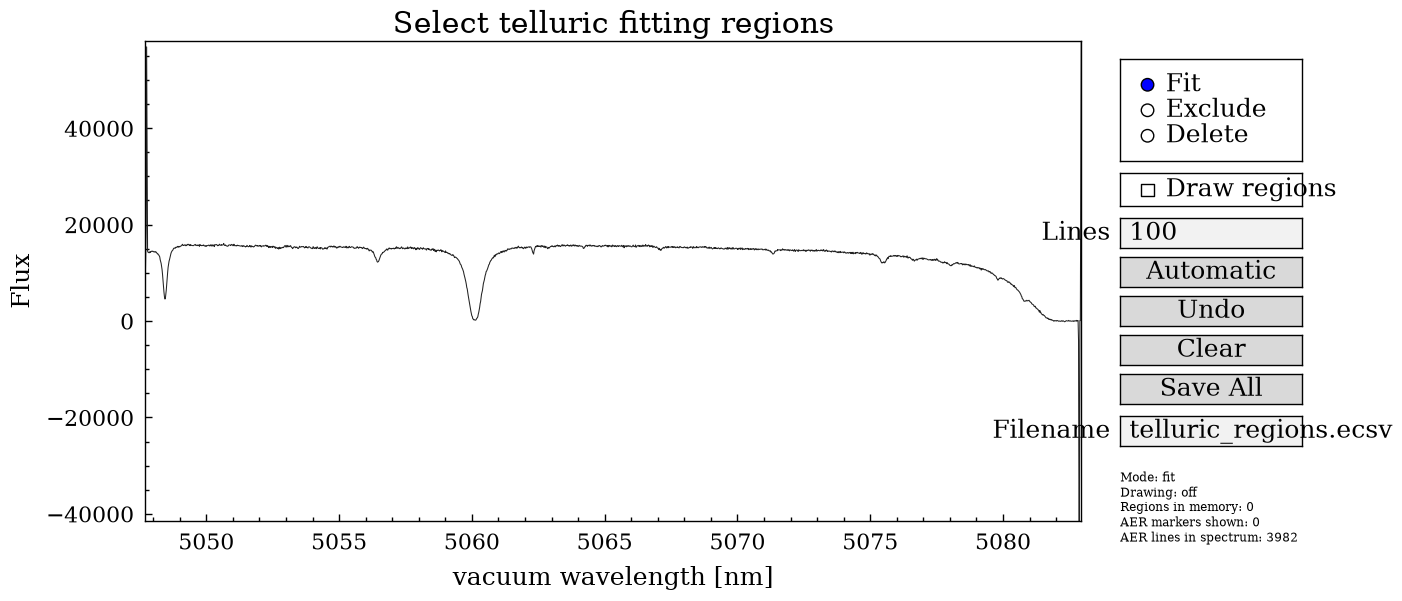

In [2]:
region_file = REGION_DIR / "fitting_regions_test.ecsv"

# note: need to specify wavelength and flux columns
spectrum = load_spectrum(
    FILE,
    hdu=1, #first chip
    wavelength_col="03_01_WL",
    flux_col="03_01_SPEC",
    uncertainty_col="03_01_ERR",
    wavelength_unit="nm",
    wavelength_medium="vacuum",
    save_header=False,
)
def make_region_file(spectrum, path):
    selector = select_telluric_regions(
        spectrum, show=True,
        automatic_region_half_width_pixels=20, #default is 12
    )
    selector.add_automatic_fit_regions(400)  # Per order; overlapping windows are merged.
    selector.save(path)
    selector.close()


make_region_file(spectrum, region_file)
#elect_telluric_regions(spectrum, output_path=region_file)


In [3]:
result = correct(
    input_path=FILE,
    hdu=1,
    wavelength_col="03_01_WL",
    flux_col="03_01_SPEC",
    uncertainty_col="03_01_ERR",
    wavelength_unit="nm",
    wavelength_medium="vacuum",
    region_file=region_file,
)

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 5.0475953 to 5.0829446 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2041 fitted
  invalid/quality-masked pixels: 7
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 20219 selected from 20219
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 8 automatic segments; 1 physical groups; maximum width=0.005 micron
Continuum and optimizer
  c

It works well with these parameters!

WL range in observed spectrum: 5047.595295733535 - 5082.9446280355705 nm
WL range in corrected spectrum: 5047.595295733535 - 5082.9446280355705 nm


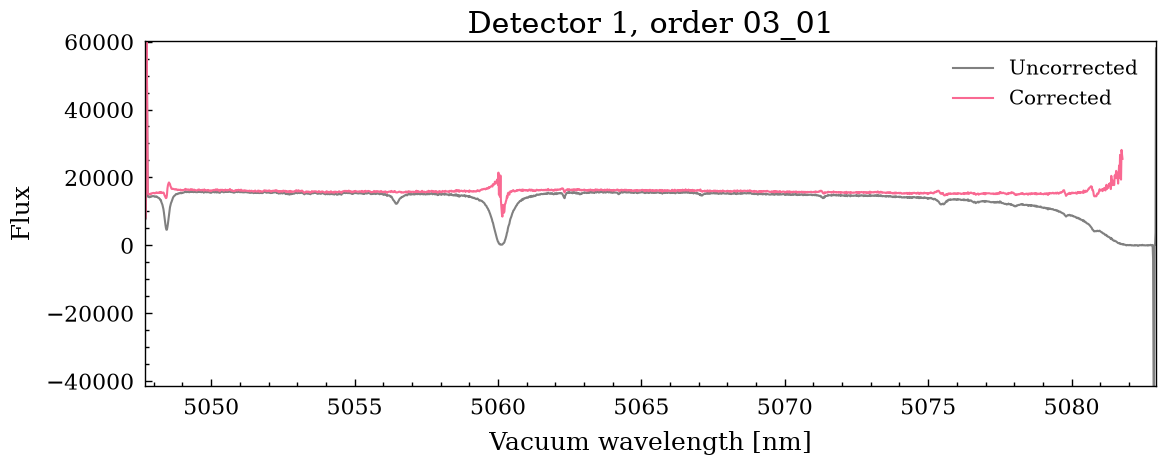

In [4]:
observed = result.spectrum.to_unit("nm")
corrected = result.corrected.to_unit("nm")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(observed.wavelength, observed.flux, color="0.5", label="Uncorrected")
ax.plot(corrected.wavelength, corrected.flux, label="Corrected")
print(f'WL range in observed spectrum: {observed.wavelength.min()} - {observed.wavelength.max()} nm')
print(f'WL range in corrected spectrum: {corrected.wavelength.min()} - {corrected.wavelength.max()} nm')
ax.set(xlabel="Vacuum wavelength [nm]", ylabel="Flux", title="Detector 1, order 03_01")
ax.legend()
fig.tight_layout()
plt.savefig(REGION_DIR / "order_03_01_correction.png", dpi=300)
plt.show()

## With fix_full_correction method

The problem encountered earlier, in reading_fits.ipynb, is that the telluric wavelength range does not match the wavelength range of the detector orders for this particular file.

In this method, the correct function uses many more parameters. Is that what causes it not to work? Or is it the combination of orders?

### Step 1 - use correct function with more parameters, as done in fix_full_correction, but only on 1 order

In [5]:
result = correct(
    spectrum=spectrum, 
    region_file=region_file, 
    auto_segment=True, #``True`` separates FITS orders/detectors and wavelength discontinuities into physical groups, then divides wide groups into bounded radiative-transfer chunks. Molecular columns remain global, continuum coefficients remain local to numerical chunks, and automatic wavelength polynomials are shared across every chunk from the same physical group. ``False`` fits the input as one segment and may exceed grid limits.
    segment_size=0.01, # in microns, maximum numerical radiative-transfer chunk width in microns
    continuum_order=2, #
    solve_continuum_linear=True, #`True`` always selects this stable profiled approach, while ``False`` includes continuum coefficients in the nonlinear parameter vector
    loss="soft_l1", # soft_l1 is standard in new version; Controls how residuals influence the fit. ``linear`` is ordinary squared-residual least squares and is the statistically preferred default for a clean, well-masked spectrum with reliable uncertainties. ``soft_l1`` is usually appropriate for a mostly clean spectrum containing a limited number of cosmic rays, bad pixels, or unmasked spectral features because it reduces their influence without ignoring normal residuals. ``huber`` is another moderate robust loss, while ``cauchy`` and ``arctan`` suppress large outliers more strongly. Robust loss cannot repair generally poor calibration, wavelength misalignment, incorrect uncertainties, or an unsuitable atmospheric model.
    f_scale=1.0, #Residual scale separating normal points from downweighted outliers for robust losses;
    fit_wavelength_shift=False, 
    fit_segment_wavelength_polynomial=True, # ``True`` fits one wavelength-correction polynomial per detected physical order/detector group and shares it across that group's numerical chunks; use this when line residuals show within-order wavelength distortion, and do not combine it with global or constant per-group wavelength fitting.
    segment_wavelength_polynomial_order=2, #Degree of each physical-group wavelength polynomial
    wavelength_shift_bounds=(-0.0002, 0.0002),  # Microns: +/-0.2 nm. ``None`` uses ``(-3, 3)`` detector pixels for automatic model selection or the legacy micron bounds for explicit wavelength models; supplied values are pixels in automatic mode and microns in explicit mode.
    lsf_sigma_pixels="auto", #
    fit_lsf_sigma=True, # ``"auto"`` refines an automatically estimated ``lsf_sigma_pixels`` when telluric lines are available but keeps an explicitly numeric sigma fixed; ``True`` always fits Gaussian sigma and ``False`` always keeps the resolved value fixed.
    high_resolution_grid=True, # ``True`` computes, convolves, and rebins an oversampled internal model; ``False`` evaluates directly at observed samples.
    high_resolution_oversampling=5, #Approximate internal samples per observed pixel when ``high_resolution_grid=True``.
    min_transmission=0.1,  # Leave near-opaque absorption uncorrected (NaN).
)


PyMolFit effective fit configuration
Data
  input: cr2res_obs_nodding_extracted_combined
  wavelength range: 5.0475953 to 5.0829446 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2041 fitted
  invalid/quality-masked pixels: 7
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 20219 selected from 20219
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 4 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  continuum order: 2
  continuum solver: linear (requested=lin

WL range in observed spectrum: 5047.595295733535 - 5082.9446280355705 nm
WL range in corrected spectrum: 5047.595295733535 - 5082.9446280355705 nm


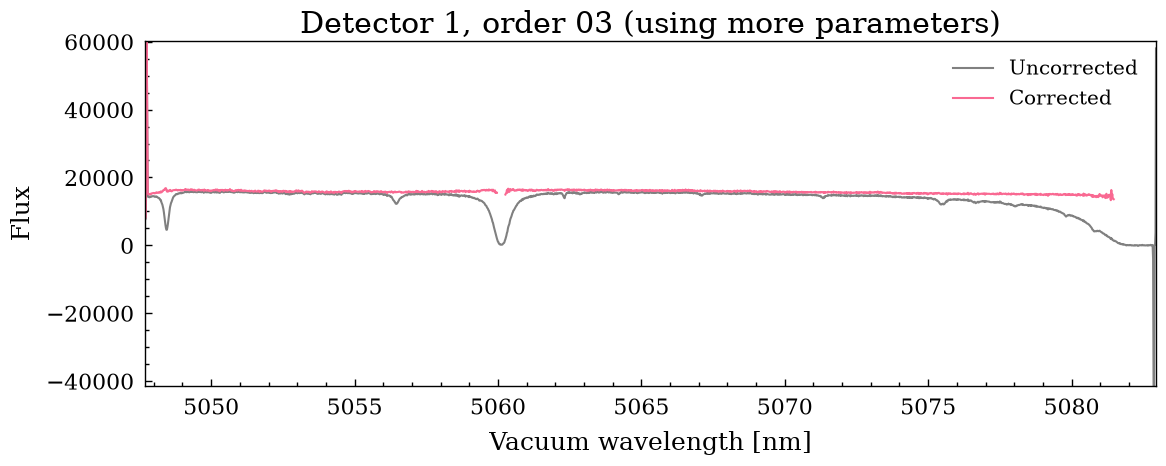

In [6]:
observed = result.spectrum.to_unit("nm")
corrected = result.corrected.to_unit("nm")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(observed.wavelength, observed.flux, color="0.5", label="Uncorrected")
ax.plot(corrected.wavelength, corrected.flux, label="Corrected")
print(f'WL range in observed spectrum: {observed.wavelength.min()} - {observed.wavelength.max()} nm')
print(f'WL range in corrected spectrum: {corrected.wavelength.min()} - {corrected.wavelength.max()} nm')
ax.set(xlabel="Vacuum wavelength [nm]", ylabel="Flux", title="Detector 1, order 03 (using more parameters)")
ax.legend()
fig.tight_layout()
plt.savefig(REGION_DIR / "order_03_01_correction.png", dpi=300)
plt.show()

The result is different from the one above, we lose the absorption/emission around 5060 nm and the climbing at the end. But it covers the full wavelength range, so we don't get the same problem as before. But what if we combine all orders?

Below is directly copied from fix_full_correction:

1 CHIP1.INT1
2 CHIP2.INT1
3 CHIP3.INT1
Correcting chip_1_03_01 (1/15)


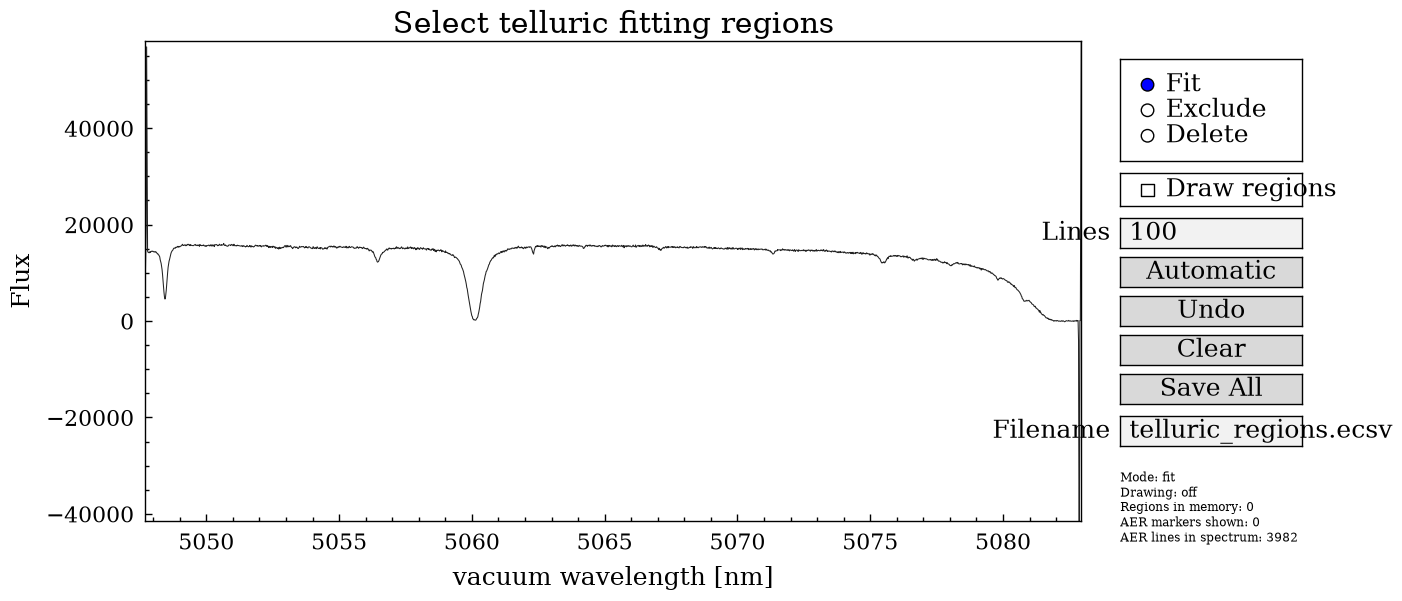

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 5.0475953 to 5.0829446 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2041 fitted
  invalid/quality-masked pixels: 7
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 20219 selected from 20219
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 4 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  co

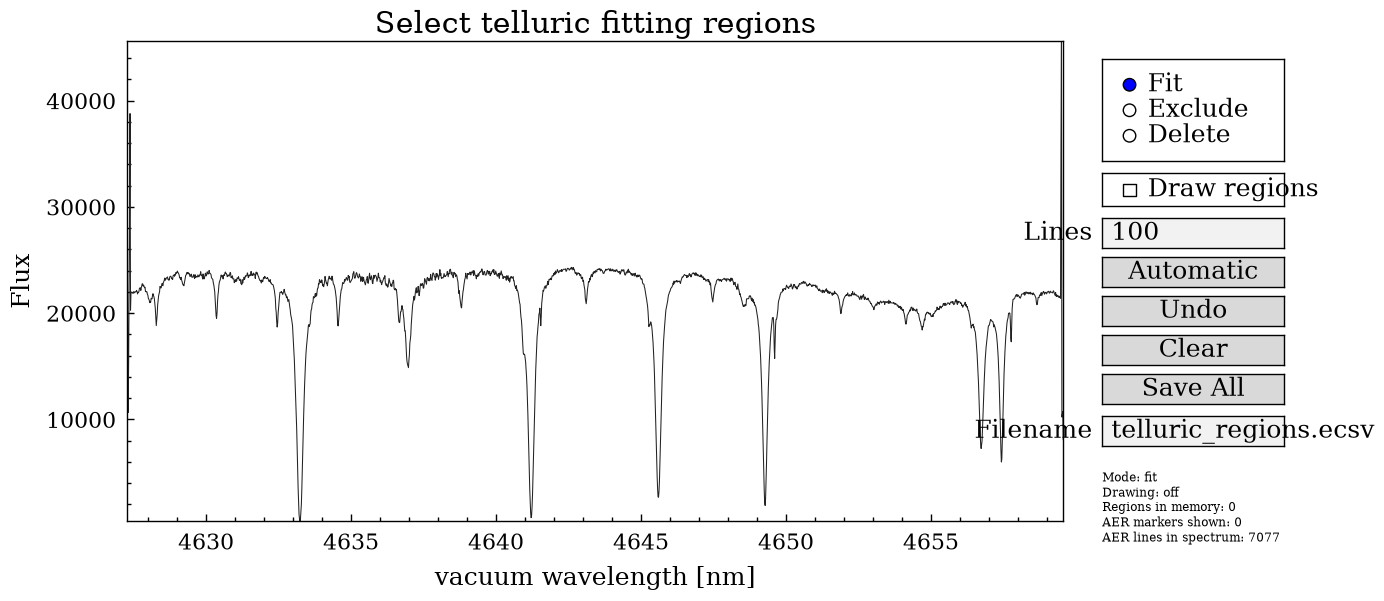

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 4.627216 to 4.6595623 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2043 fitted
  invalid/quality-masked pixels: 5
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 32311 selected from 32311
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 4 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  con

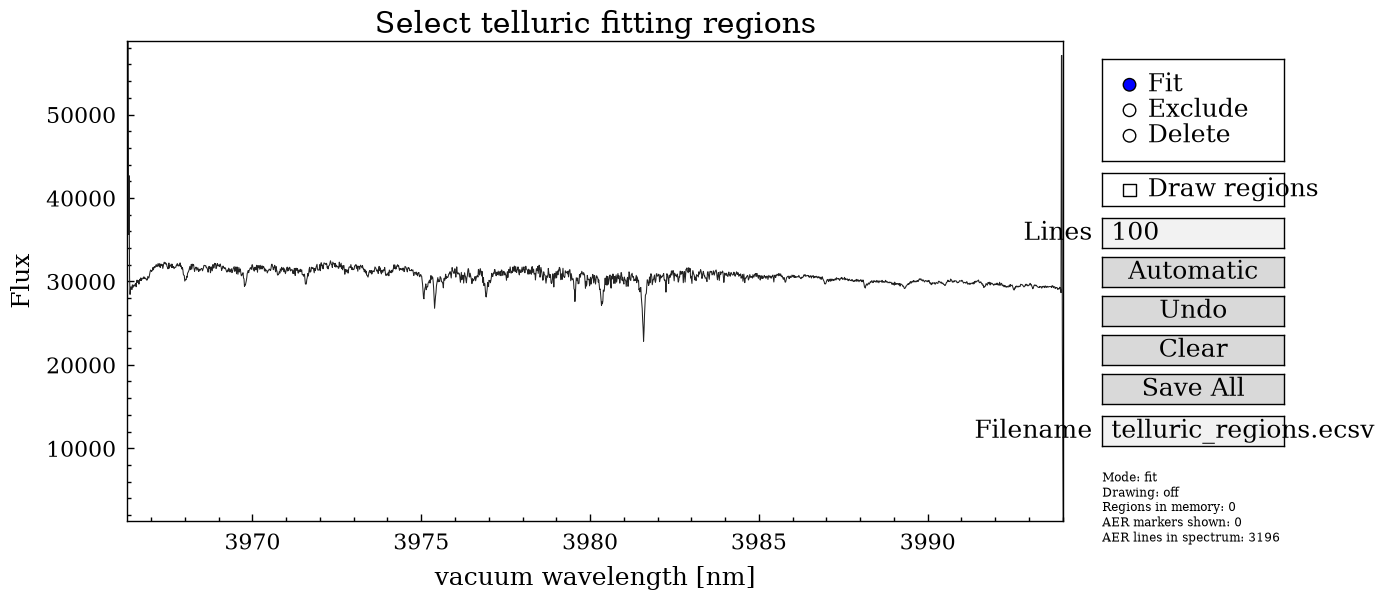

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.9662504 to 3.9940146 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2042 fitted
  invalid/quality-masked pixels: 6
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 11922 selected from 11922
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

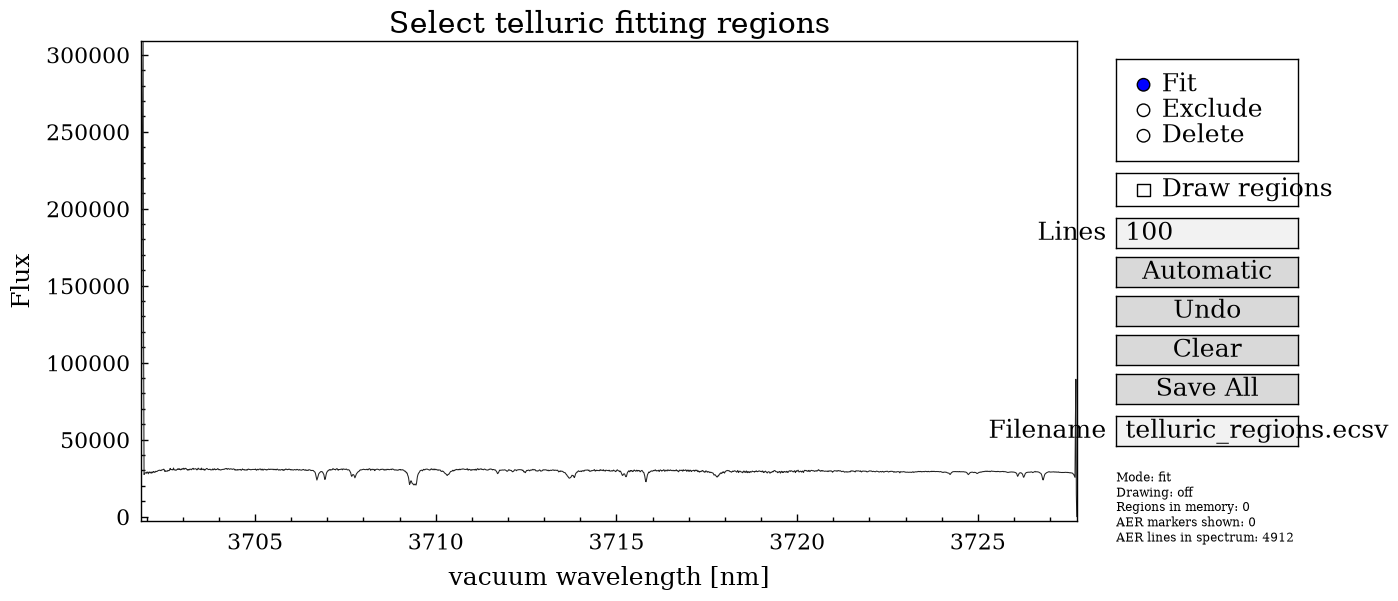

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.7018366 to 3.7277519 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2040 fitted
  invalid/quality-masked pixels: 8
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 18462 selected from 18462
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

/home/alst3712/.venv/lib/python3.13/site-packages/pymolfit/workflow.py:1246: RuntimeWarning: Residual telluric alignment remains larger than 0.25 pixel in the median physical group; inspect fit_quality diagnostics.
  result = _correct_spectrum_workflow(


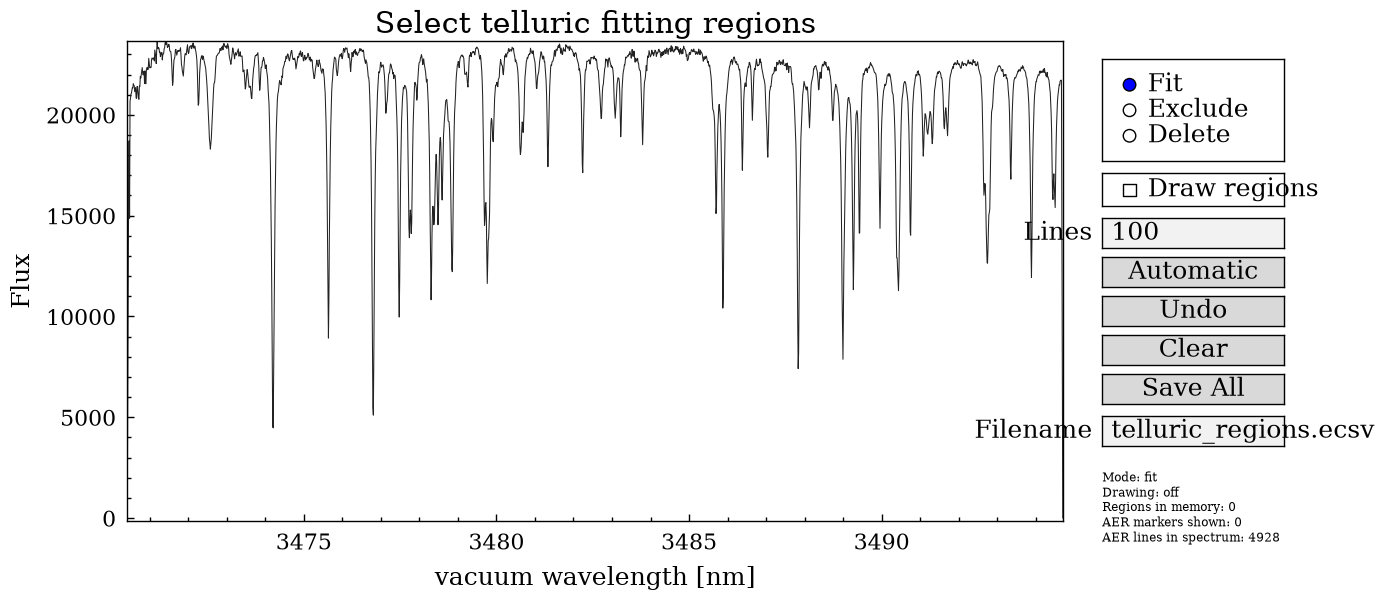

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.4704161 to 3.4947248 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2026 fitted
  invalid/quality-masked pixels: 8
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 17927 selected from 17927
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (2 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

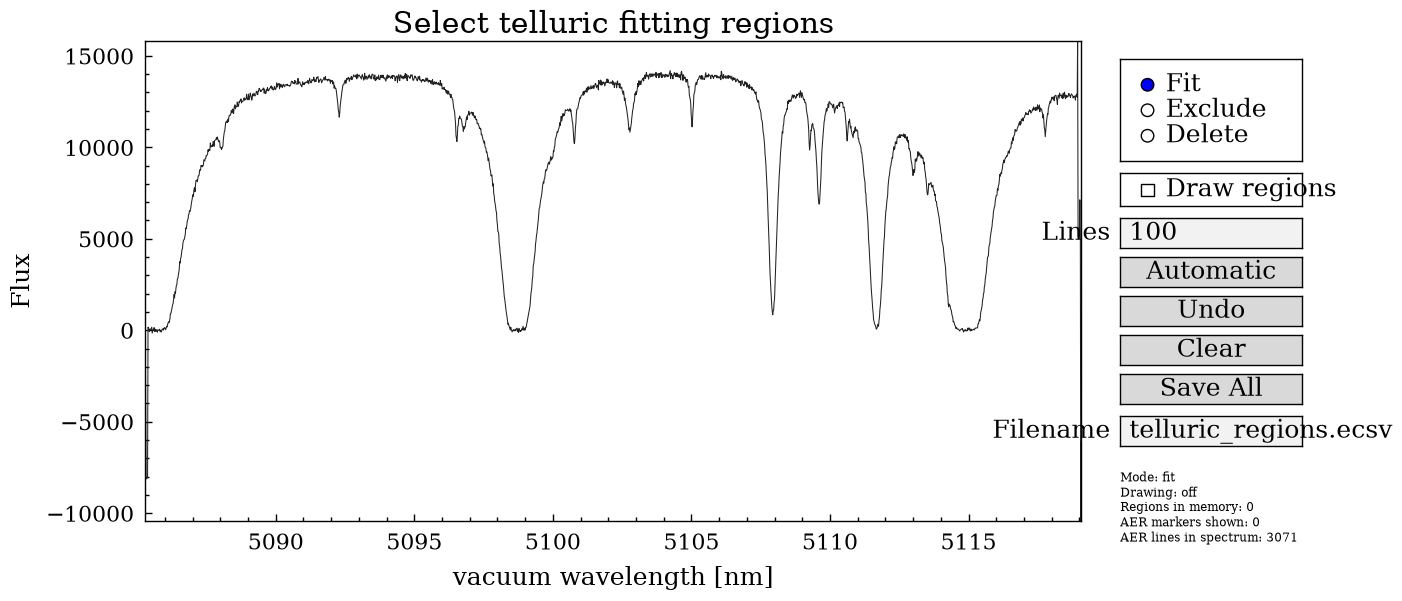

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 5.0852552 to 5.1190667 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2039 fitted
  invalid/quality-masked pixels: 9
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 16907 selected from 16907
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 4 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  co

/home/alst3712/.venv/lib/python3.13/site-packages/pymolfit/workflow.py:1246: RuntimeWarning: Residual telluric alignment remains larger than 0.25 pixel in the median physical group; inspect fit_quality diagnostics.
  result = _correct_spectrum_workflow(


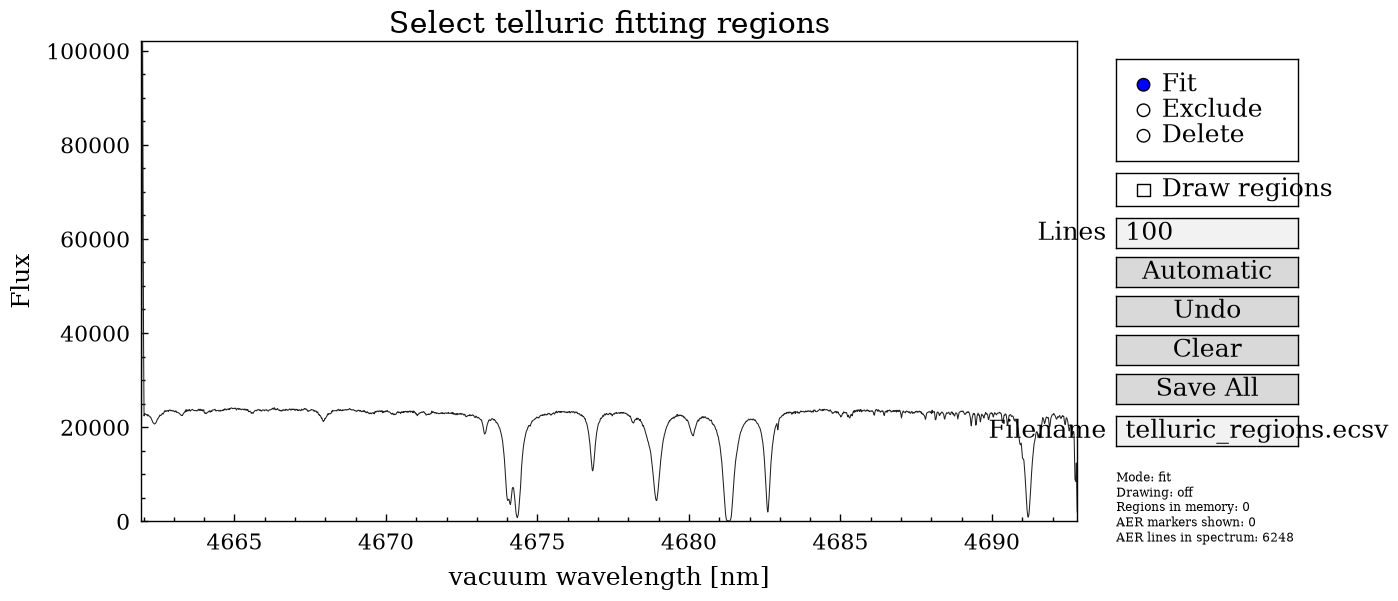

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 4.6618939 to 4.6928158 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2008 fitted
  invalid/quality-masked pixels: 6
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 30939 selected from 30939
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (4 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 4 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  co

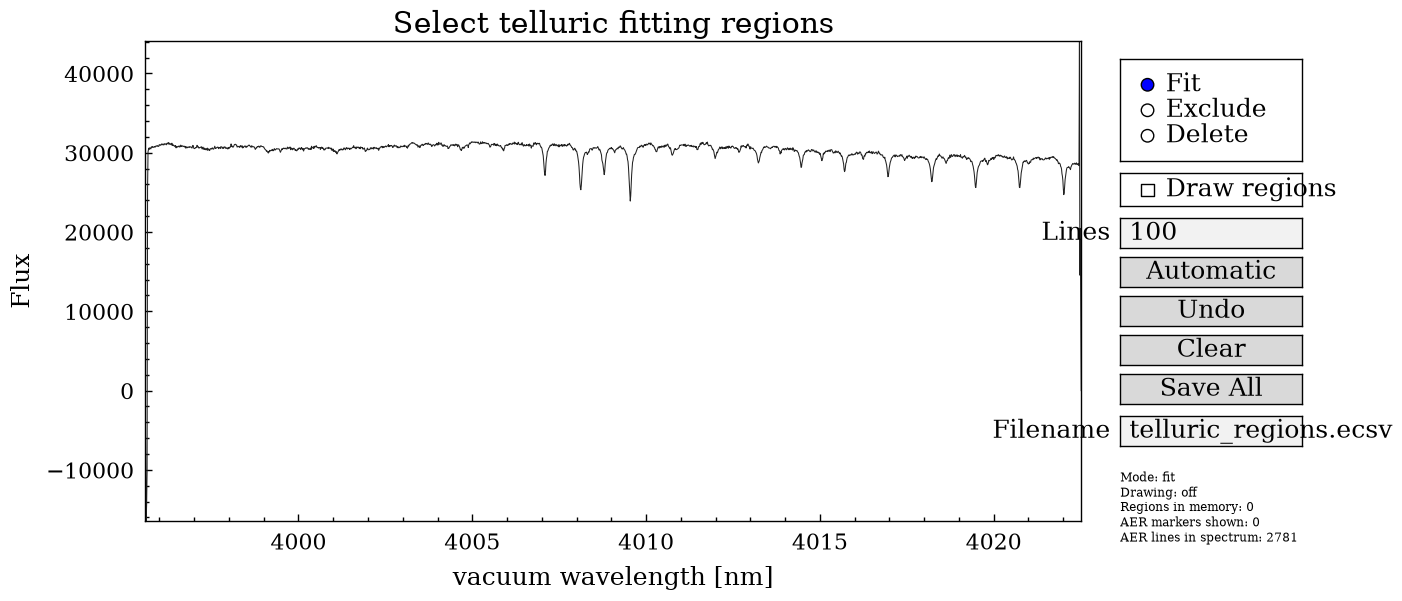

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.9955784 to 4.0225181 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2041 fitted
  invalid/quality-masked pixels: 6
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 12131 selected from 12131
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (2 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

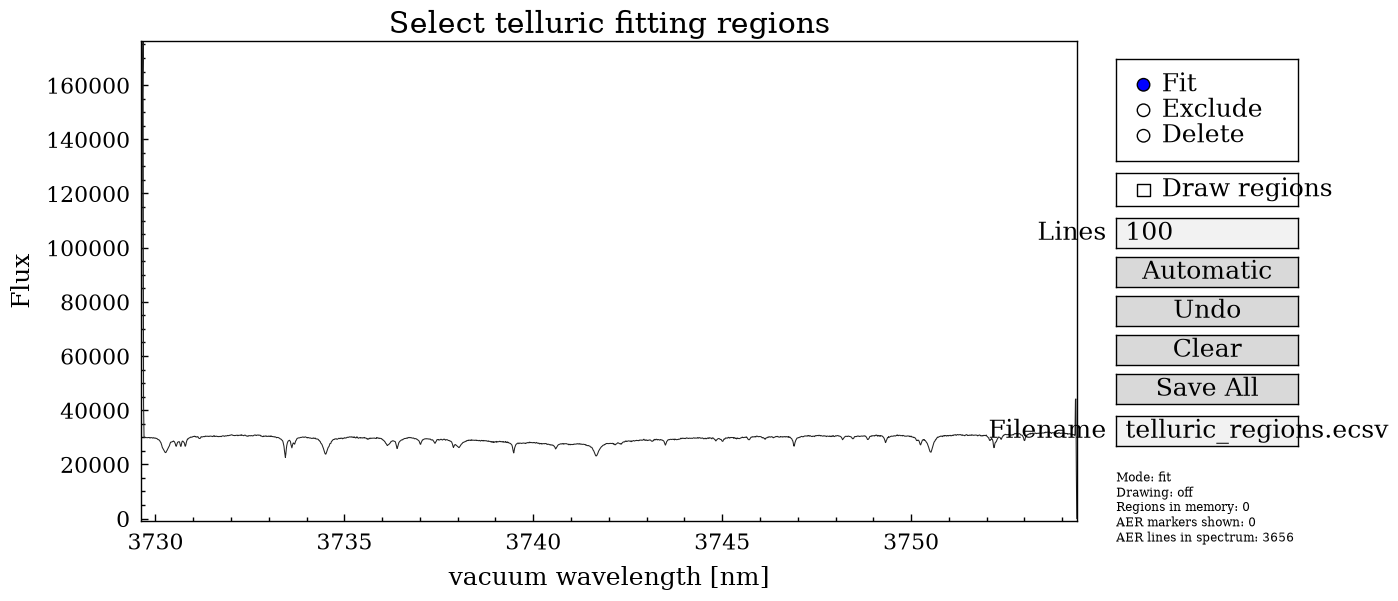

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.7296108 to 3.7543977 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2036 fitted
  invalid/quality-masked pixels: 7
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 15469 selected from 15469
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (3 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

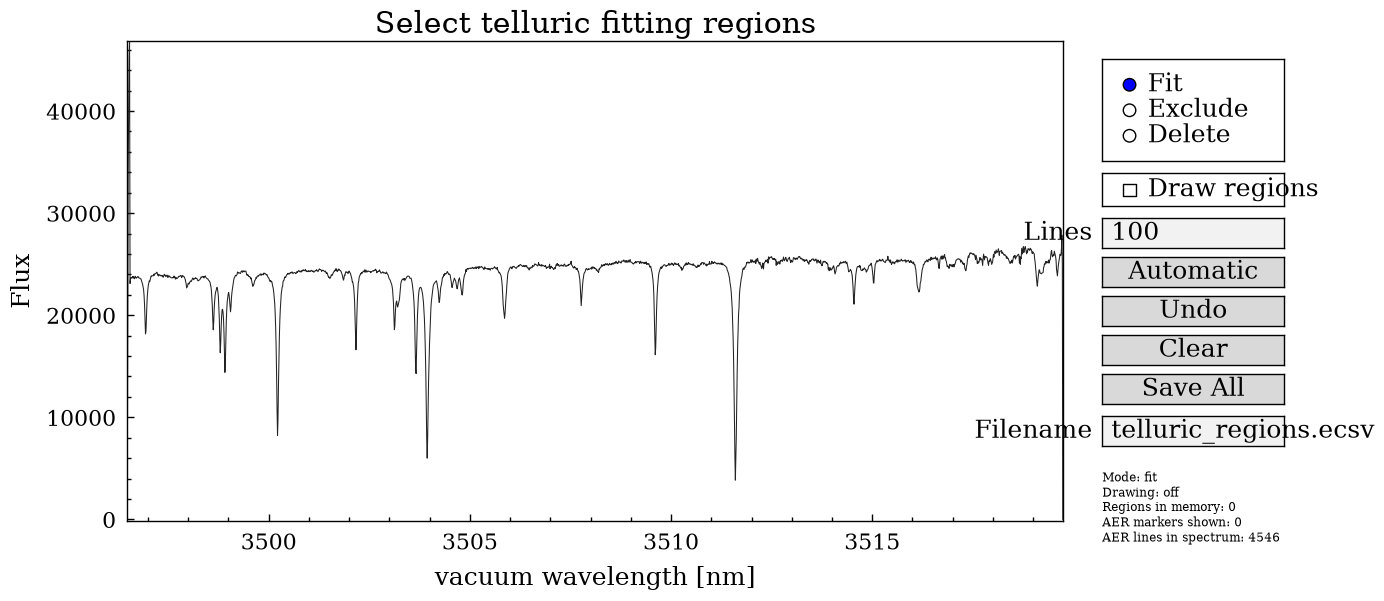

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.4964836 to 3.5197586 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2041 fitted
  invalid/quality-masked pixels: 7
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 16919 selected from 16919
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

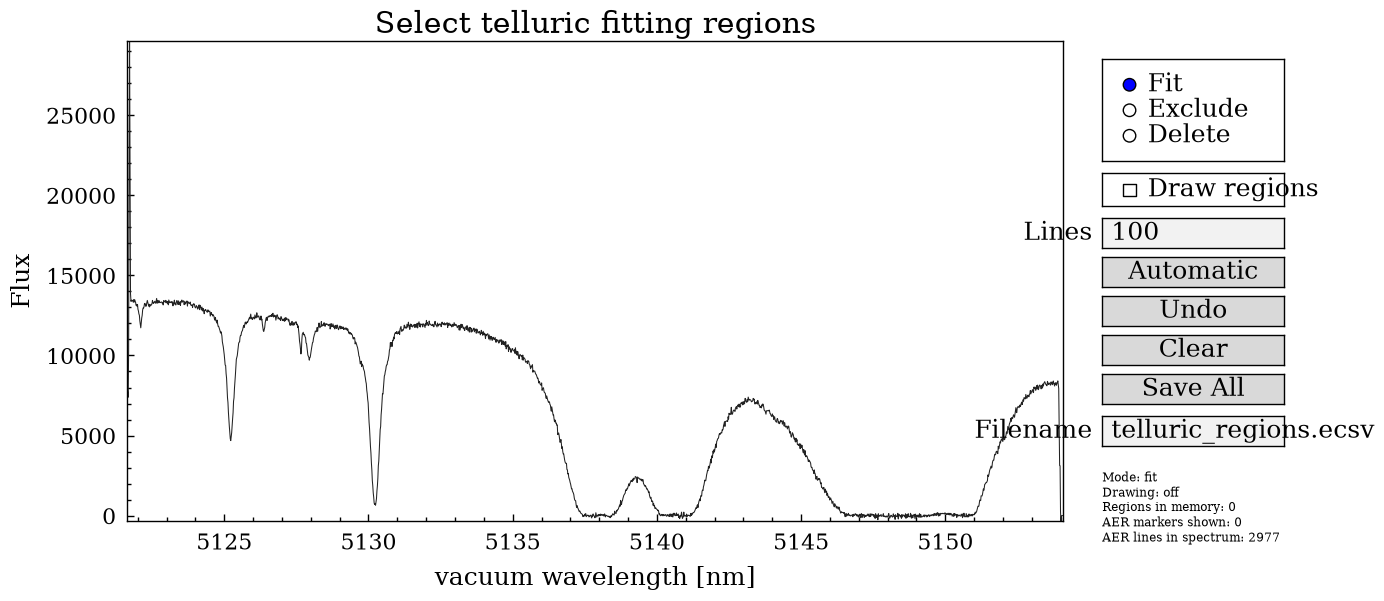

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 5.1215223 to 5.1540874 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2036 fitted
  invalid/quality-masked pixels: 12
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 14907 selected from 14907
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 4 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  c

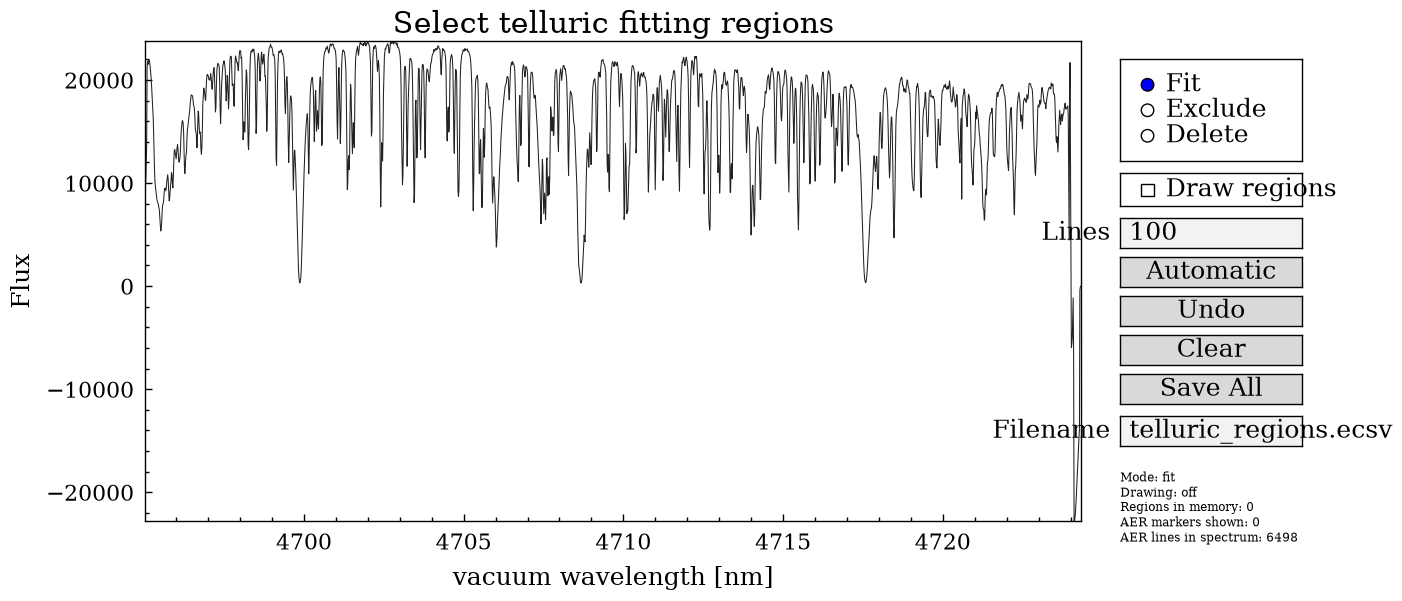

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 4.6949572 to 4.7243342 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2023 fitted
  invalid/quality-masked pixels: 25
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 32871 selected from 32871
  species: CH4, CO, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  c

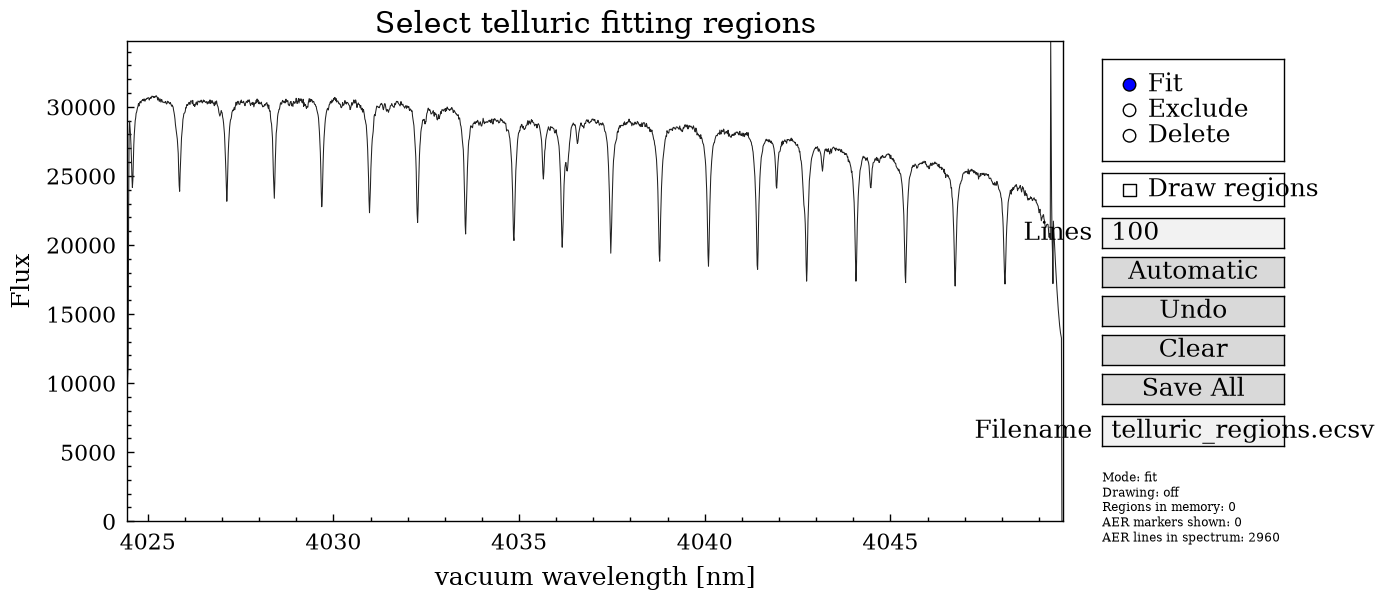

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 4.0244107 to 4.0496547 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2023 fitted
  invalid/quality-masked pixels: 25
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 12516 selected from 12516
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  conti

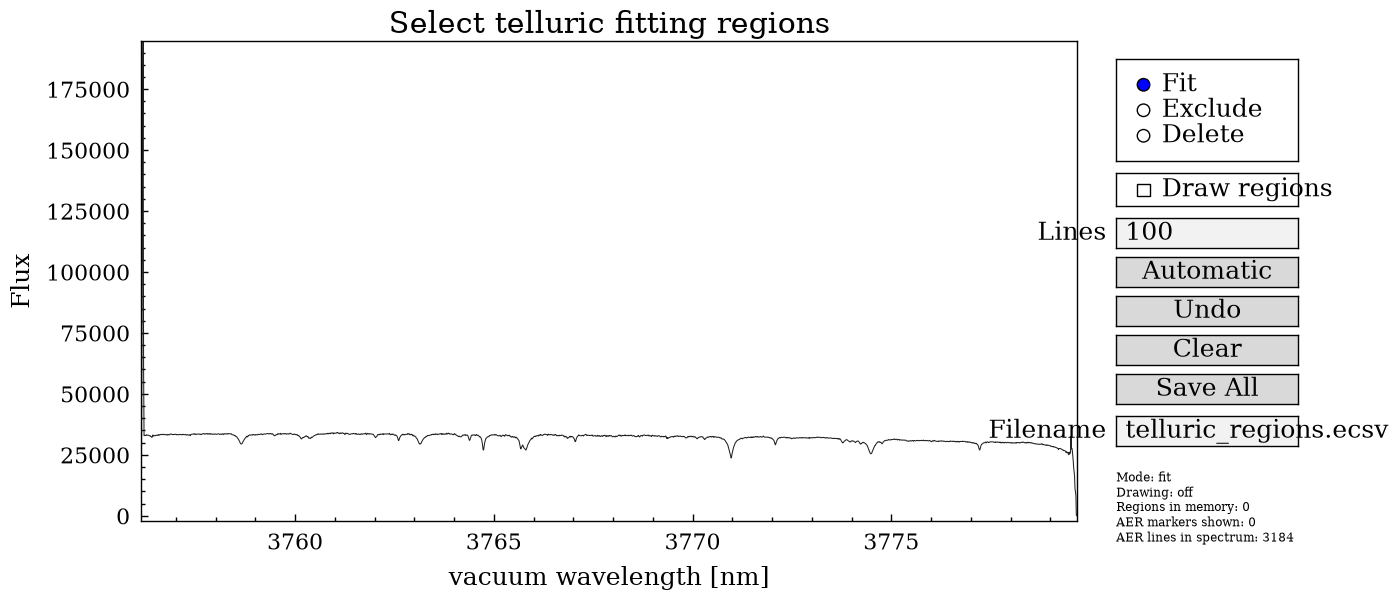

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.7561185 to 3.7796787 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2039 fitted
  invalid/quality-masked pixels: 9
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 13611 selected from 13611
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

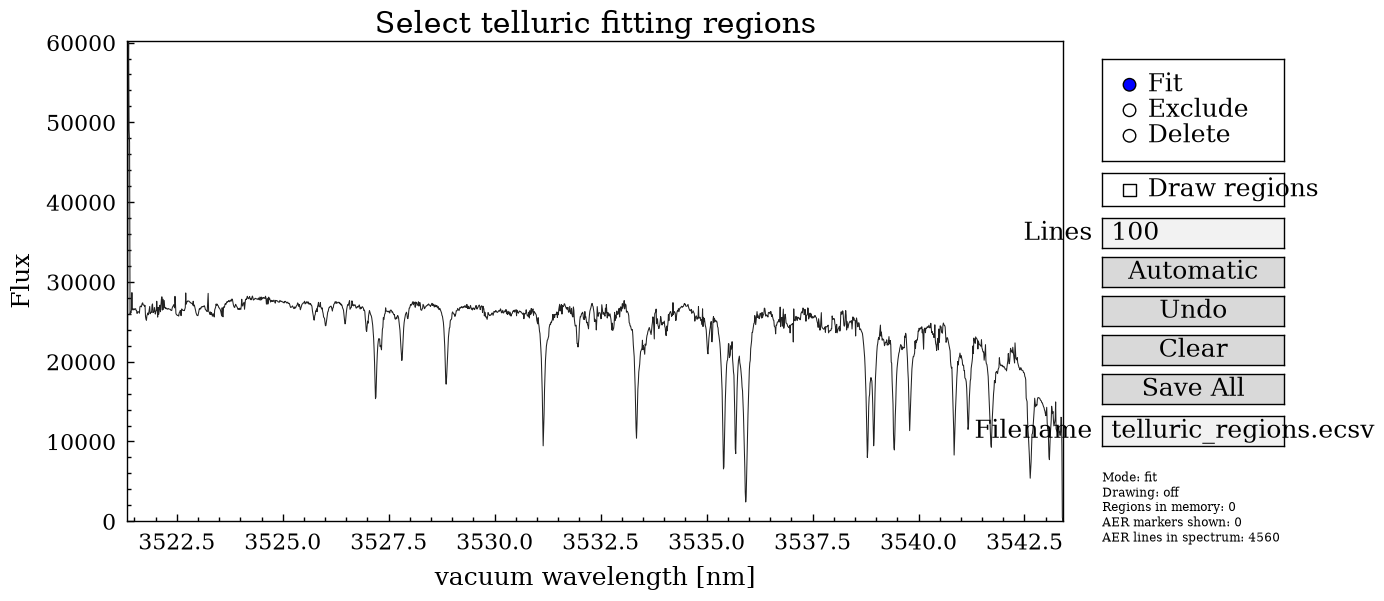

PyMolFit effective fit configuration
Data
  input: /srv/local/anba6163/Clean_Data/2022-12-23_M4318/extr/cr2res_obs_nodding_extracted_combined.fits
  wavelength range: 3.5213316 to 3.5434144 micron
  wavelength frame: observatory-frame vacuum
  pixels: 2048 total, 2042 fitted
  invalid/quality-masked pixels: 6
  uncertainty weighting: yes
Line data
  source: aer_lnfl_tape8
  lines: 17063 selected from 17063
  species: CH4, CO2, H2O, N2O, O3
Atmosphere
  physical layers: 48
  MIPAS profile: equ
  GDAS source: eso_time_local
  observation time UTC: 2022-12-23T03:45:45.000
  observatory: Paranal; lat=-24.6268 deg, lon=-70.4045 deg, alt=2648 m
  observation airmass: 1.1255 (incorporated into atmospheric layer path lengths)
  additional opacity airmass multiplier: 1
Fit masks and segmentation
  fit ranges: custom (1 intervals)
  excluded ranges (observatory vacuum micron): none
  segmentation: 3 automatic segments; 1 physical groups; maximum width=0.01 micron
Continuum and optimizer
  contin

In [7]:
#for 1 file, you can do the following to correct all orders in one go:
from astropy.io import fits
import numpy as np

def load_all_orders(path):
    orders = {}
    with fits.open(path) as hdus:
        for chip, hdu in enumerate(hdus[1:], 1): #for each of the three chips...
            print(chip, hdu.name)
            for name in hdu.columns.names:
                if name.endswith("_WL"):
                    #for each of the 5/6 orders...
                    order = name.removesuffix("_WL")
                    orders[f"chip_{chip}_{order}"] = Spectrum(
                        wavelength=hdu.data[name],
                        flux=hdu.data[f"{order}_SPEC"],
                        uncertainty=hdu.data[f"{order}_ERR"],
                        #group_id=np.zeros(hdu.data[name].size, dtype=int),
                        wavelength_unit="nm",
                        wavelength_medium="vacuum",
                        meta={"source": str(path)},
                    )
    return orders


def make_region_file(spectrum, path):
    selector = select_telluric_regions(
        spectrum, show=True,
        automatic_region_half_width_pixels=20, #default is 12
    )
    selector.add_automatic_fit_regions(400)  # Per order; overlapping windows are merged.
    selector.save(path)
    selector.close()

if __name__ == "__main__":
    orders = load_all_orders(FILE)
    REGION_DIR.mkdir(exist_ok=True)
    #results = {}

    output_file = REGION_DIR / f"tellurics_corrected_new.dat"

    corrected_orders = []
    for index, (name, spectrum) in enumerate(orders.items(), 1):
        print(f"Correcting {name} ({index}/{len(orders)})", flush=True)
        region_file = REGION_DIR / f"{name}.ecsv" #note to self - ecsv can store stuff like units and can be used to write astropy tables
        make_region_file(spectrum, region_file)
        
        result = correct(
            spectrum=spectrum, 
            region_file=region_file, 
            auto_segment=True, #``True`` separates FITS orders/detectors and wavelength discontinuities into physical groups, then divides wide groups into bounded radiative-transfer chunks. Molecular columns remain global, continuum coefficients remain local to numerical chunks, and automatic wavelength polynomials are shared across every chunk from the same physical group. ``False`` fits the input as one segment and may exceed grid limits.
            segment_size=0.01, # in microns, maximum numerical radiative-transfer chunk width in microns
            continuum_order=2, #
            solve_continuum_linear=True, #`True`` always selects this stable profiled approach, while ``False`` includes continuum coefficients in the nonlinear parameter vector
            loss="soft_l1", # soft_l1 is standard in new version; Controls how residuals influence the fit. ``linear`` is ordinary squared-residual least squares and is the statistically preferred default for a clean, well-masked spectrum with reliable uncertainties. ``soft_l1`` is usually appropriate for a mostly clean spectrum containing a limited number of cosmic rays, bad pixels, or unmasked spectral features because it reduces their influence without ignoring normal residuals. ``huber`` is another moderate robust loss, while ``cauchy`` and ``arctan`` suppress large outliers more strongly. Robust loss cannot repair generally poor calibration, wavelength misalignment, incorrect uncertainties, or an unsuitable atmospheric model.
            f_scale=1.0, #Residual scale separating normal points from downweighted outliers for robust losses;
            fit_wavelength_shift=False, 
            fit_segment_wavelength_polynomial=True, # ``True`` fits one wavelength-correction polynomial per detected physical order/detector group and shares it across that group's numerical chunks; use this when line residuals show within-order wavelength distortion, and do not combine it with global or constant per-group wavelength fitting.
            segment_wavelength_polynomial_order=2, #Degree of each physical-group wavelength polynomial
            wavelength_shift_bounds=(-0.0002, 0.0002),  # Microns: +/-0.2 nm. ``None`` uses ``(-3, 3)`` detector pixels for automatic model selection or the legacy micron bounds for explicit wavelength models; supplied values are pixels in automatic mode and microns in explicit mode.
            lsf_sigma_pixels="auto", #
            fit_lsf_sigma=True, # ``"auto"`` refines an automatically estimated ``lsf_sigma_pixels`` when telluric lines are available but keeps an explicitly numeric sigma fixed; ``True`` always fits Gaussian sigma and ``False`` always keeps the resolved value fixed.
            high_resolution_grid=True, # ``True`` computes, convolves, and rebins an oversampled internal model; ``False`` evaluates directly at observed samples.
            high_resolution_oversampling=5, #Approximate internal samples per observed pixel when ``high_resolution_grid=True``.
            min_transmission=0.1,  # Leave near-opaque absorption uncorrected (NaN).
        )

        corrected = result.corrected.to_unit("nm")

        corrected_orders.append(np.column_stack((
                                corrected.wavelength,
                                corrected.flux,
                                corrected.uncertainty)))

    corrected_data = np.vstack(corrected_orders)


    with open(output_file, "w") as f:
        f.write("# wavelength flux error\n")

        for wavelength, flux, error in corrected_data:
            f.write(f"{wavelength:.10f} {flux:.10e} {error:.10e}\n")

    print(f"Saved corrected spectrum to {output_file}")


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1528266/4102737139.py:4: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(myfile, comment="#", names=["wavelength", "flux", "error"], delimiter='\s+')


telluric range: 3470.42 to 5154.09 nm
telluric points: 30720
original data range: 3470.42 to 5154.09 nm
total wavelength points: 30682


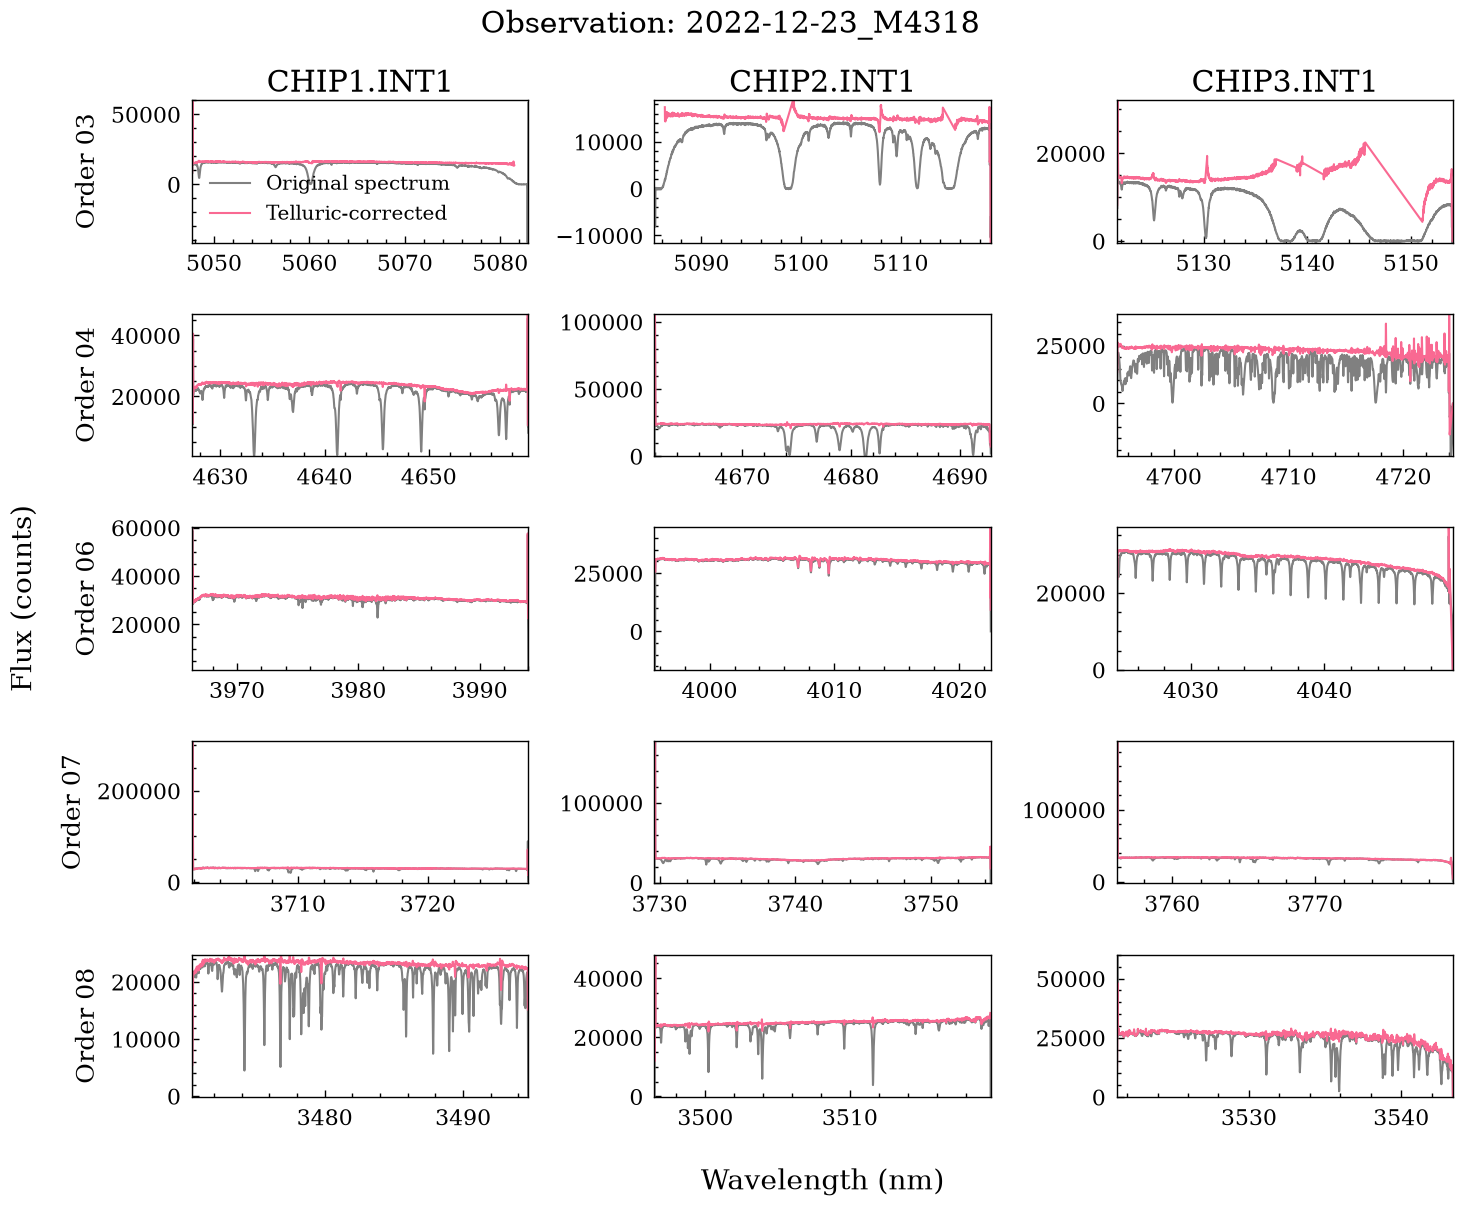

In [8]:
import pandas as pd

myfile = Path("/home/alst3712/clean_data/2022-12-23_M4318/order_regions/tellurics_corrected_new.dat")
df = pd.read_csv(myfile, comment="#", names=["wavelength", "flux", "error"], delimiter='\s+')
print(f'telluric range: {df["wavelength"].min():.2f} to {df["wavelength"].max():.2f} nm')
print(f'telluric points: {len(df)}')
date_dir = myfile.parent.parent.name
original_file = "/srv/local/anba6163/Clean_Data/" + date_dir + "/extr/cr2res_obs_nodding_extracted_combined.fits"

orders = []

with fits.open(original_file) as hdul:
    for hdu in hdul:
        if hdu.data is None or not hdu.name.startswith("CHIP"):
            continue

        columns = set(hdu.columns.names)

        for wl_col in sorted(c for c in columns if c.endswith("_WL")):

            order_id = wl_col.removesuffix("_01_WL")
            spec_col = f"{order_id}_01_SPEC"

            if spec_col not in columns:
                continue

            orders.append(
                (
                    hdu.name,
                    order_id,
                    np.asarray(hdu.data[wl_col], dtype=float).copy(),
                    np.asarray(hdu.data[spec_col], dtype=float).copy(),
                )
            )

if not orders:
    raise ValueError(f"No wavelength/spectrum orders found in {original_file}")

corrected_wavelength = df["wavelength"].to_numpy(dtype=float)

corrected_flux = df["flux"].to_numpy(dtype=float)
corrected_valid = (
    np.isfinite(corrected_wavelength) & np.isfinite(corrected_flux)
)
corrected_wavelength = corrected_wavelength[corrected_valid]
corrected_flux = corrected_flux[corrected_valid]

sort_idx = np.argsort(corrected_wavelength)
corrected_wavelength = corrected_wavelength[sort_idx]
corrected_flux = corrected_flux[sort_idx]

chips = sorted({chip_name for chip_name, _, _, _ in orders})

orders_by_chip = {
    chip: [order for order in orders if order[0] == chip]
    for chip in chips
}

n_rows = max(len(chip_orders) for chip_orders in orders_by_chip.values())

fig, axes = plt.subplots(
    n_rows,
    len(chips),
    figsize=(5 * len(chips), 2.5 * n_rows),
    squeeze=False,
    sharex=False,
    sharey=False,
)

mins = []
maxs = []
total_wl_length = []

for col, chip in enumerate(chips):
    chip_orders = orders_by_chip[chip]

    for row, (_, order_id, original_wavelength, original_flux) in enumerate(chip_orders):
        ax = axes[row, col]

        valid = np.isfinite(original_wavelength) & np.isfinite(original_flux)
        wl = original_wavelength[valid]
        mins.append(wl.min())
        maxs.append(wl.max())
        total_wl_length.append(len(wl))
        flux = original_flux[valid]

        ax.plot(wl, flux, color="grey", label="Original spectrum")

        if corrected_wavelength.size >= 2 and wl.size:
            in_order = (
                (corrected_wavelength >= wl.min())
                & (corrected_wavelength <= wl.max())
            )
            order_wavelength = corrected_wavelength[in_order]
            order_flux = corrected_flux[in_order]

            if order_wavelength.size >= 2:
                aligned = (wl >= order_wavelength.min()) & (
                    wl <= order_wavelength.max()
                )
                ax.plot(
                    wl[aligned],
                    np.interp(wl[aligned], order_wavelength, order_flux),
                    label="Telluric-corrected",
                )

        if col == 0:
            ax.set_ylabel(f"Order {order_id}")


        if col == 0 and row == 0:
            ax.legend()

        if row == 0:
            ax.set_title(chip)


        if col == 1 and row == n_rows - 1:
            ax.text(
                0.5, -0.5,
                "Wavelength (nm)",
                fontsize=20,
                ha="center",
                va="top",
                transform=ax.transAxes,
            )

        if col == 0 and row == round(n_rows / 2):
            ax.text(
                -0.5, 0.5,
                "Flux (counts)",
                fontsize=20,
                ha="center",
                va="center",
                rotation=90,
                transform=ax.transAxes,
            )

        # ax.set_title(f"{chip} — order {order_id}")
        # ax.set_xlabel("Wavelength (nm)")
        # ax.set_ylabel("Flux (counts)")
        # ax.legend(loc="upper right")

    for row in range(len(chip_orders), n_rows):
        axes[row, col].set_visible(False)

print(f"original data range: {min(mins):.2f} to {max(maxs):.2f} nm")
print(f"total wavelength points: {sum(total_wl_length)}")
fig.suptitle(f"Observation: {date_dir}")
fig.tight_layout()
plt.show()